In [2]:
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

In [3]:
len(text)

1115394

In [4]:
print(text[:1000])  #Print the first 1000 characters of the text

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



In [5]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print("All the unique characters:", ''.join(chars))
print("\nVocabulary size:", vocab_size)

All the unique characters: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz

Vocabulary size: 65


Create a mapping from characters to integers

In [6]:
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }

encoding = lambda s: [stoi[c] for c in s]  # encoder: take a string, output a list of integers
decoding = lambda l: ''.join([itos[i] for i in l])  # decoder: take a list of integers, output a string

print(encoding("hii there"))
# print(decoding([46, 47, 47, 1, 58, 46, 43, 56, 43]))
print(decoding(encoding("hii there")))

[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


In [7]:
import torch
data = torch.tensor(encoding(text), dtype=torch.long)
print(data.shape, data.dtype)
print(data[:1000])  #Print the first 1000 characters of the text as integers

torch.Size([1115394]) torch.int64
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59,  1, 39, 56, 43,  1, 39, 50, 50,
         1, 56, 43, 57, 53, 50, 60, 43, 42,  1, 56, 39, 58, 46, 43, 56,  1, 58,
        53,  1, 42, 47, 43,  1, 58, 46, 39, 52,  1, 58, 53,  1, 44, 39, 51, 47,
        57, 46, 12,  0,  0, 13, 50, 50, 10,  0, 30, 43, 57, 53, 50, 60, 43, 42,
         8,  1, 56, 43, 57, 53, 50, 60, 43, 42,  8,  0,  0, 18, 47, 56, 57, 58,
         1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 18, 47, 56, 57, 58,  6,  1, 63,
        53, 59,  1, 49, 52, 53, 61,  1, 15, 39, 47, 59, 57,  1, 25, 39, 56, 41,
      

Split up the data into train and validation sets

In [8]:
n = int(0.9*len(data))  # first 90% will be train, rest val
train_data = data[:n]
val_data = data[n:]

In [9]:
block_size = 8  # how many characters to consider at once (chunk size)
train_data[:block_size+1]  # show the first block_size+1 characters as integers

tensor([18, 47, 56, 57, 58,  1, 15, 47, 58])

In [10]:
x = train_data[:block_size]
y = train_data[1:block_size+1]

for t in range(block_size):
    context = x[:t+1]
    target = y[t]
    print(f"when input is {context} the target: {target}")

when input is tensor([18]) the target: 47
when input is tensor([18, 47]) the target: 56
when input is tensor([18, 47, 56]) the target: 57
when input is tensor([18, 47, 56, 57]) the target: 58
when input is tensor([18, 47, 56, 57, 58]) the target: 1
when input is tensor([18, 47, 56, 57, 58,  1]) the target: 15
when input is tensor([18, 47, 56, 57, 58,  1, 15]) the target: 47
when input is tensor([18, 47, 56, 57, 58,  1, 15, 47]) the target: 58


In [11]:
torch.manual_seed(1337)
batch_size = 4  # how many independent sequences will we process in parallel?
block_size = 8  # what is the maximum context length for predictions?

def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data

    ix = torch.randint(len(data) - block_size, (batch_size,)) #this randomly selects 4 starting indices from the data tensor, ensuring that we have enough characters left to create a full block of size block_size. The result is a tensor of shape (batch_size,) containing the starting indices for each sequence in the batch.
    
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    return x, y

xb, yb = get_batch('train')

print('inputs:')
print(xb.shape)
print(xb)

print('targets:')
print(yb.shape)
print(yb)

inputs:
torch.Size([4, 8])
tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]])
targets:
torch.Size([4, 8])
tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39]])


In [12]:
for b in range(batch_size):  # batch dimension
    for t in range(block_size):  # time dimension
        context = xb[b, :t+1]
        target = yb[b, t]
        print(f"when input is {context.tolist()} the target: {target.item()}")

when input is [24] the target: 43
when input is [24, 43] the target: 58
when input is [24, 43, 58] the target: 5
when input is [24, 43, 58, 5] the target: 57
when input is [24, 43, 58, 5, 57] the target: 1
when input is [24, 43, 58, 5, 57, 1] the target: 46
when input is [24, 43, 58, 5, 57, 1, 46] the target: 43
when input is [24, 43, 58, 5, 57, 1, 46, 43] the target: 39
when input is [44] the target: 53
when input is [44, 53] the target: 56
when input is [44, 53, 56] the target: 1
when input is [44, 53, 56, 1] the target: 58
when input is [44, 53, 56, 1, 58] the target: 46
when input is [44, 53, 56, 1, 58, 46] the target: 39
when input is [44, 53, 56, 1, 58, 46, 39] the target: 58
when input is [44, 53, 56, 1, 58, 46, 39, 58] the target: 1
when input is [52] the target: 58
when input is [52, 58] the target: 1
when input is [52, 58, 1] the target: 58
when input is [52, 58, 1, 58] the target: 46
when input is [52, 58, 1, 58, 46] the target: 39
when input is [52, 58, 1, 58, 46, 39] the t

In [13]:
print(xb) # inputs to the transformer
print(yb) # expected outputs

tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]])
tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39]])


Simplest baseline: Bigram language model, loss, generation

>- A BigramLanguageModel is a simple language model that predicts the next token based only on the current token.

>- The key **Limitation**: It only considers the current token, not the entire preceding sentence.

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
torch.manual_seed(1337)

class BigramLanguageModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        # idx and targets are both (B,T) tensor of integers
        logits = self.token_embedding_table(idx)  # (B, T, C) where C = vocab_size

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T) #PyTorch's cross_entropy() expects the predictions in the shape (number_of_examples, number_of_classes)
            loss = F.cross_entropy(logits, targets) #assigns a relatively high probability to the correct answer, so the loss is low

        return logits, loss
    
    def generate(self, idx, max_new_tokens):
        # idx is (B,T) array of indices in the current context
        for _ in range(max_new_tokens):
            # get the predictions
            logits, loss = self(idx)
            # focus only on the last time step
            logits = logits[:, -1, :]  # becomes (B,C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1)  # (B,C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1)  # (B,1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1)  # (B,T+1)
        return idx

model = BigramLanguageModel(vocab_size)
logits, loss = model(xb, yb)
print(logits.shape) # (B*T, C)
print(loss)

print(decoding
    (model.generate
        (idx=torch.zeros((1, 1), dtype=torch.long),
        max_new_tokens=100
    )[0].tolist()
))

torch.Size([32, 65])
tensor(4.8786, grad_fn=<NllLossBackward0>)

SKIcLT;AcELMoTbvZv C?nq-QE33:CJqkOKH-q;:la!oiywkHjgChzbQ?u!3bLIgwevmyFJGUGp
wnYWmnxKWWev-tDqXErVKLgJ


In [15]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

In [16]:
batch_size = 32
for steps in range(10000):
    # sample a batch of data
    xb, yb = get_batch('train')

    # evaluate the loss
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    print(f"step {steps}: train loss {loss.item():.4f}")

step 0: train loss 4.6924
step 1: train loss 4.6641
step 2: train loss 4.7657
step 3: train loss 4.7066
step 4: train loss 4.5957
step 5: train loss 4.7101
step 6: train loss 4.7137
step 7: train loss 4.6869
step 8: train loss 4.7001
step 9: train loss 4.7183
step 10: train loss 4.7156
step 11: train loss 4.6843
step 12: train loss 4.7456
step 13: train loss 4.7357
step 14: train loss 4.6662
step 15: train loss 4.5862
step 16: train loss 4.7146
step 17: train loss 4.6720
step 18: train loss 4.7150
step 19: train loss 4.7449
step 20: train loss 4.6302
step 21: train loss 4.7076
step 22: train loss 4.6707
step 23: train loss 4.5826
step 24: train loss 4.7395
step 25: train loss 4.6748
step 26: train loss 4.8056
step 27: train loss 4.7499
step 28: train loss 4.6920
step 29: train loss 4.6044
step 30: train loss 4.7218
step 31: train loss 4.7416
step 32: train loss 4.6100
step 33: train loss 4.6628
step 34: train loss 4.7301
step 35: train loss 4.7384
step 36: train loss 4.6882
step 37: tr

In [17]:
print(decoding(model.generate(idx=torch.zeros((1, 1), dtype=torch.long), max_new_tokens=500)[0].tolist()))


lso br. ave aviasurf my, yxMPZI ivee iuedrd whar ksth y h bora s be hese, woweee; the! KI 'de, ulseecherd d o blllando;LUCEO, oraingofof win!
RIfans picspeserer hee tha,
TOFonk? me ain ckntoty ded. bo'llll st ta d:
ELIS me hurf lal y, ma dus pe athouo
BEY:! Indy; by s afreanoo adicererupa anse tecorro llaus a!
OLeneerithesinthengove fal amas trr
TI ar I t, mes, n IUSt my w, fredeeyove
THek' merer, dd
We ntem lud engitheso; cer ize helorowaginte the?
Thak orblyoruldvicee chot, p,
Bealivolde Th li


!

In [18]:
torch.manual_seed(1337)
B,T,C = 4,8,2
x = torch.randn(B,T,C)
x.shape

torch.Size([4, 8, 2])

In [19]:
x[0]

tensor([[ 0.1808, -0.0700],
        [-0.3596, -0.9152],
        [ 0.6258,  0.0255],
        [ 0.9545,  0.0643],
        [ 0.3612,  1.1679],
        [-1.3499, -0.5102],
        [ 0.2360, -0.2398],
        [-0.9211,  1.5433]])

In [20]:
xbow = torch.zeros((B,T,C))
for b in range(B):
    for t in range(T):
        xprev = x[b, :t+1]  # (t, C)
        xbow[b, t] = torch.mean(xprev, 0)  # take the mean over the time dimension

In [21]:
xbow[0]

tensor([[ 0.1808, -0.0700],
        [-0.0894, -0.4926],
        [ 0.1490, -0.3199],
        [ 0.3504, -0.2238],
        [ 0.3525,  0.0545],
        [ 0.0688, -0.0396],
        [ 0.0927, -0.0682],
        [-0.0341,  0.1332]])

this is all well and good but **very inefficient**

--

The mathematical **trick** in Self Attention

In [22]:
torch.tril(torch.ones(3, 3))

tensor([[1., 0., 0.],
        [1., 1., 0.],
        [1., 1., 1.]])

In [23]:
# version 1
torch.manual_seed(42)
a = torch.tril(torch.ones(3, 3))
a = a / torch.sum(a, 1, keepdim=True)  # normalize the rows
b = torch.randint(0, 10, (3, 2)).float()
c = a @ b  # matrix multiply, but only take the lower triangular part of a into account

print("A:")
print(a)
print("B:")
print(b)
print("C:")
print(c)

A:
tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])
B:
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
C:
tensor([[2.0000, 7.0000],
        [4.0000, 5.5000],
        [4.6667, 5.3333]])


In [24]:
# version 2
weights = torch.tril(torch.ones(T, T))
weights = weights / weights.sum(1, keepdim=True)  # normalize the rows
xbow2 = weights @ x # (B, T, C) @ (B, T, C) --> (B, T, C)
xbow2[0] #same as xbow[0]

tensor([[ 0.1808, -0.0700],
        [-0.0894, -0.4926],
        [ 0.1490, -0.3199],
        [ 0.3504, -0.2238],
        [ 0.3525,  0.0545],
        [ 0.0688, -0.0396],
        [ 0.0927, -0.0682],
        [-0.0341,  0.1332]])

In [25]:
torch.allclose(xbow, xbow2, atol=1e-6)  # check that the two methods give the same result

True

In [40]:
# version 3
tril = torch.tril(torch.ones(T, T))
weights = torch.zeros((T, T))
weights = weights.masked_fill(tril == 0, float('-inf'))  # fill the upper triangular part with -inf
weights = F.softmax(weights, dim=-1)  # apply softmax to get probabilities
xbow3 = weights @ x # (B, T, C) @ (B, T, C) --> (B, T, C)
xbow3[0] #same as xbow[0]

tensor([[ 0.1808, -0.0700],
        [-0.0894, -0.4926],
        [ 0.1490, -0.3199],
        [ 0.3504, -0.2238],
        [ 0.3525,  0.0545],
        [ 0.0688, -0.0396],
        [ 0.0927, -0.0682],
        [-0.0341,  0.1332]])

In [39]:
torch.allclose(xbow, xbow3, atol=1e-6)  # check that the two methods give the same result

True

In [ ]:
# version 4
torch.manual_seed(1337)
B,T,C = 4,8,32
x = torch.randn(B,T,C)

# let's see a single Head perform self-attention
head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)
k = key(x)   # (B, T, head_size)
q = query(x) # (B, T, head_size)
v = value(x) # (B, T, head_size)
weights = q @ k.transpose(-2, -1) * (head_size ** -0.5)  # (B, T, head_size) @ (B, head_size, T) --> (B, T, T)

tril = torch.tril(torch.ones(T, T))
# weights = torch.zeros((T, T))

weights = weights.masked_fill(tril == 0, float('-inf'))  # fill the upper triangular part with -inf (makes sure that the model cannot look into the future)

weights = F.softmax(weights, dim=-1)  # apply softmax to get probabilities
# out = weights @ x # (B, T, C) @ (B, T, C) --> (B, T, C)
out = weights @ v # (B, T, head_size)

out.shape

torch.Size([4, 8, 16])

`(head_size ** -0.5)` Scaling is used for controlling the variance.

In [72]:
weights[0] # the attention weights for the first example in the batch

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3966, 0.6034, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3069, 0.2892, 0.4039, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3233, 0.2175, 0.2443, 0.2149, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1479, 0.2034, 0.1663, 0.1455, 0.3369, 0.0000, 0.0000, 0.0000],
        [0.1259, 0.2490, 0.1324, 0.1062, 0.3141, 0.0724, 0.0000, 0.0000],
        [0.1598, 0.1990, 0.1140, 0.1125, 0.1418, 0.1669, 0.1061, 0.0000],
        [0.0845, 0.1197, 0.1078, 0.1537, 0.1086, 0.1146, 0.1558, 0.1553]],
       grad_fn=<SelectBackward0>)

Notes:

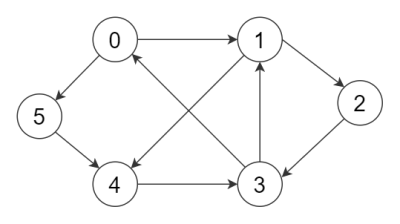

1. Attention is a **communication mechanism**. Can be seen as nodes in a directed graph looking at each other and aggregating information with a weighted sum from all nodes that point to them, with data-dependent weights.
2. There is no notion of space. Attention simply acts over a set of vectors. This is why we need to positionally encode tokens.
3. Each example across batch dimension is of course processed completely independently and never "talk" to each other
4. In an "encoder" attention block just delete the single line that does masking with `tril`, allowing all tokens to communicate. This block here is called a "decoder" attention block because it has triangular masking, and is usually used in autoregressive settings, like language modeling.
5. "self-attention" just means that the keys and values are produced from the same source as queries. In "cross-attention", the queries still get produced from x, but the keys and values come from some other, external source (e.g. an encoder module)
6. "Scaled" attention additional divides `weights` by 1/sqrt(head_size). This makes it so when input Q,K are unit variance, weights will be unit variance too and Softmax will stay diffuse and not saturate too much. Illustration below